# **3. Chuẩn bị đặc trưng**

Đánh giá đặc trưng, tạo đặc trưng mới (lịch, cạnh tranh, cụm cửa hàng, xu hướng – mùa vụ, độ trễ), chia tập dữ liệu và lưu lại cho bước huấn luyện.

In [1]:
# [UPDATED] Gom toàn bộ import lên đầu; notebook tự đọc dữ liệu sạch nên chạy độc lập được
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.signal import periodogram
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess

FIG_DIR = Path('figures')  # [UPDATED] Thư mục lưu hình để chèn vào báo cáo
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    """[UPDATED] Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)


PROCESSED_DIR = Path('data/processed')
TRAIN_END = '2014-12-31'  # [UPDATED] Mốc chia tập dùng chung cho cả hai mô hình
VALID_END = '2015-04-30'

my_data = pd.read_csv(PROCESSED_DIR / 'rossmann_clean.csv', parse_dates=['Date'], dtype={'StateHoliday': str})
# [UPDATED] Biến đổi log đặt ở bước chuẩn bị dữ liệu (trước đây nằm trong notebook EDA)
my_data['Sales'] = np.log1p(my_data['Sales'])
print(my_data.shape)

(844338, 17)


## 3.1 Đánh giá mức độ quan trọng của đặc trưng

Dùng dữ liệu 01–08/2013 để xem cột nào liên quan nhiều đến doanh thu, bằng hai cách: Random Forest và Mutual Information.

In [2]:
# [UPDATED] Dùng chung một bộ dữ liệu cho Random Forest và Mutual Information; bỏ cột Date vì mô hình không đọc được kiểu ngày
sample = my_data[(my_data['Date'] > '2013-01-01') & (my_data['Date'] < '2013-09-01')]
y_sample = sample['Sales']
X_sample = sample.drop(columns=['Sales', 'Date'])
# [UPDATED] select_dtypes(exclude='number') bắt được cả kiểu chữ 'str' mới của pandas 3 (select_dtypes('object') bỏ sót)
for col in X_sample.select_dtypes(exclude='number').columns:
    X_sample[col], _ = X_sample[col].factorize()
print(X_sample.shape)

(225624, 15)


Customers                    0.7682
StoreType                    0.0501
CompetitionDistance          0.0466
Promo                        0.0331
Store                        0.0247
Assortment                   0.0209
Promo2SinceWeek              0.0137
CompetitionOpenSinceYear     0.0112
CompetitionOpenSinceMonth    0.0111
DayOfWeek                    0.0086
Promo2SinceYear              0.0063
PromoInterval                0.0033
SchoolHoliday                0.0012
Promo2                       0.0009
StateHoliday                 0.0001
dtype: float64

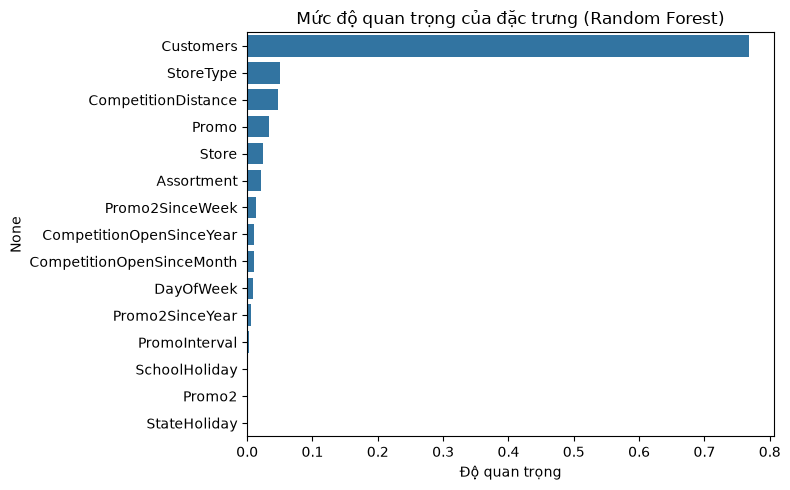

In [3]:
# [UPDATED] Bỏ pipeline + TargetEncoder: các cột chữ đã được đổi sang số ở trên, Random Forest dùng trực tiếp được
rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=0, n_jobs=-1)
rf.fit(X_sample, y_sample)
rf_importance = pd.Series(rf.feature_importances_, index=X_sample.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=rf_importance.values, y=rf_importance.index)
plt.title('Mức độ quan trọng của đặc trưng (Random Forest)')
plt.xlabel('Độ quan trọng')
save_fig('rf_importance')
rf_importance.round(4)

Customers                    0.7044
Store                        0.6231
Promo                        0.0958
CompetitionDistance          0.0507
DayOfWeek                    0.0384
Promo2SinceWeek              0.0356
Promo2SinceYear              0.0283
PromoInterval                0.0167
Promo2                       0.0157
StoreType                    0.0145
CompetitionOpenSinceMonth    0.0110
CompetitionOpenSinceYear     0.0104
Assortment                   0.0062
SchoolHoliday                0.0038
StateHoliday                 0.0001
dtype: float64

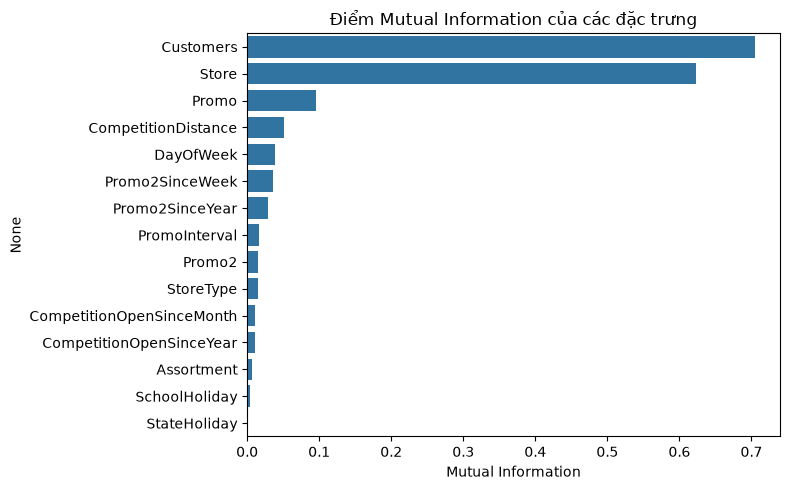

In [4]:
# [UPDATED] Lấy mẫu 50.000 dòng để tính Mutual Information nhanh hơn (kết quả xếp hạng gần như không đổi)
mi_X = X_sample.sample(50_000, random_state=0)
mi_y = y_sample.loc[mi_X.index]
is_discrete = np.array([np.issubdtype(dtype, np.integer) for dtype in mi_X.dtypes])
mi_scores = pd.Series(mutual_info_regression(mi_X, mi_y, discrete_features=is_discrete, random_state=0),
                      index=mi_X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=mi_scores.values, y=mi_scores.index)
plt.title('Điểm Mutual Information của các đặc trưng')
plt.xlabel('Mutual Information')
save_fig('mi_scores')
mi_scores.round(4)

**Nhận xét:** cả hai cách đều cho thấy `Customers` quan trọng nhất (RF: 0,77; MI: 0,70), nhưng đây là rò rỉ dữ liệu (chỉ biết sau khi bán) nên phải **loại bỏ**. `PromoInterval` có độ quan trọng thấp ở cả hai cách nên cũng loại. Các cột còn lại được giữ vì khi kết hợp với nhau vẫn có ích cho mô hình.

In [5]:
my_data = my_data.drop(columns=['PromoInterval', 'Customers'])

## 3.2 Đặc trưng lịch và cạnh tranh

In [6]:
my_data['Day'] = my_data['Date'].dt.day
my_data['Month'] = my_data['Date'].dt.month
my_data['Year'] = my_data['Date'].dt.year

# [UPDATED] Tính số THÁNG đối thủ đã mở (trước đây chỉ tính theo năm và có thể ra số âm); bằng 0 nếu không rõ hoặc đối thủ chưa mở
months_open = (12 * (my_data['Year'] - my_data['CompetitionOpenSinceYear'])
               + (my_data['Month'] - my_data['CompetitionOpenSinceMonth']))
my_data['CompetitorLongevity'] = months_open.where(my_data['CompetitionOpenSinceYear'] > 0, 0).clip(lower=0)
my_data = my_data.drop(columns=['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear'])
my_data[['Date', 'Day', 'Month', 'Year', 'CompetitorLongevity']].head()

,Date,Day,Month,Year,CompetitorLongevity
0,2013-01-02,2,1,2013,52.0
1,2013-01-03,3,1,2013,52.0
2,2013-01-04,4,1,2013,52.0
3,2013-01-05,5,1,2013,52.0
4,2013-01-07,7,1,2013,52.0


## 3.3 Phân cụm cửa hàng bằng K-Means

Gom các cửa hàng có đặc điểm giống nhau (loại cửa hàng, mức đa dạng hàng hoá, khoảng cách đối thủ, Promo2) thành nhóm. Số cụm được chọn theo chỉ số Silhouette.

2    0.301
3    0.319
4    0.383
5    0.418
6    0.475
7    0.487
8    0.490
dtype: float64

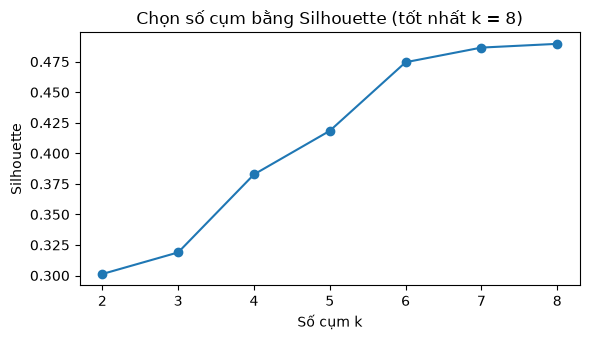

In [7]:
# [UPDATED] Phân cụm theo CỬA HÀNG (mỗi cửa hàng 1 dòng) thay vì theo từng dòng cửa hàng–ngày; gộp 4 mô hình K-Means cũ thành 1
stores = my_data.drop_duplicates('Store').set_index('Store')
store_features = pd.get_dummies(stores[['StoreType', 'Assortment']], dtype=float)
store_features['LogDistance'] = np.log1p(stores['CompetitionDistance'])
store_features['Promo2'] = stores['Promo2']
store_scaled = StandardScaler().fit_transform(store_features)

# [UPDATED] Chọn số cụm k bằng Silhouette (trước đây cố định k = 5 không có căn cứ)
silhouette = pd.Series({k: silhouette_score(store_scaled, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(store_scaled))
                        for k in range(2, 9)})
best_k = silhouette.idxmax()
plt.figure(figsize=(6, 3.5))
silhouette.plot(marker='o')
plt.xlabel('Số cụm k')
plt.ylabel('Silhouette')
plt.title(f'Chọn số cụm bằng Silhouette (tốt nhất k = {best_k})')
save_fig('silhouette')
silhouette.round(3)

In [8]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit(store_scaled)
stores['Cluster'] = kmeans.labels_
my_data['Cluster'] = my_data['Store'].map(stores['Cluster'])
stores.groupby('Cluster').agg(
    SoCuaHang=('StoreType', 'size'),
    LoaiCuaHangChinh=('StoreType', lambda s: s.mode()[0]),
    DaDangHangHoaChinh=('Assortment', lambda s: s.mode()[0]),
    KhoangCachTrungVi=('CompetitionDistance', 'median'),
    TyLePromo2=('Promo2', 'mean'),
).round(2)

,SoCuaHang,LoaiCuaHangChinh,DaDangHangHoaChinh,KhoangCachTrungVi,TyLePromo2
Cluster,,,,,
0,221,a,c,2330.0,0.46
1,128,d,a,4425.0,0.60
2,194,a,a,1670.0,0.00
3,9,b,b,860.0,0.44
4,220,d,c,5345.0,0.57
5,148,c,a,1660.0,0.51
6,187,a,a,1310.0,1.00
7,8,b,a,1195.0,0.12


**Nhận xét:** Silhouette tăng dần và gần như đi ngang từ k = 6 đến k = 8 (0,475 → 0,490), nên chọn k = 8. Các cụm chủ yếu được phân theo loại cửa hàng, mức đa dạng hàng hoá và việc có tham gia Promo2 hay không. Nhãn cụm được thêm làm đặc trưng `Cluster`.

## 3.4 Xu hướng và mùa vụ

Tính doanh thu trung bình (log) của toàn chuỗi theo ngày, rồi dùng hồi quy tuyến tính với đặc trưng xu hướng, thứ trong tuần và chuỗi Fourier theo năm để mô tả phần "đều đặn" của doanh thu.

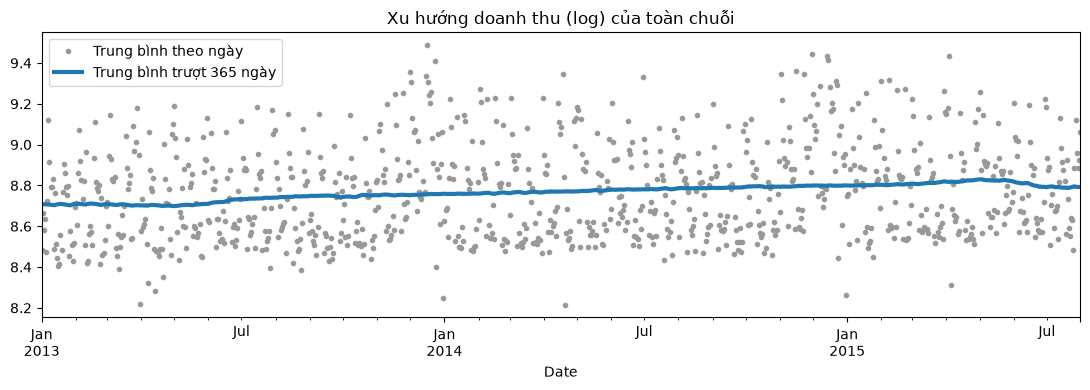

In [9]:
daily_sales = my_data.groupby('Date')['Sales'].mean().asfreq('D')
moving_average = daily_sales.rolling(window=365, center=True, min_periods=183).mean()
ax = daily_sales.plot(style='.', color='0.6', figsize=(11, 4), label='Trung bình theo ngày')
moving_average.plot(ax=ax, linewidth=3, label='Trung bình trượt 365 ngày')
ax.set_title('Xu hướng doanh thu (log) của toàn chuỗi')
ax.legend()
save_fig('trend_ma365')

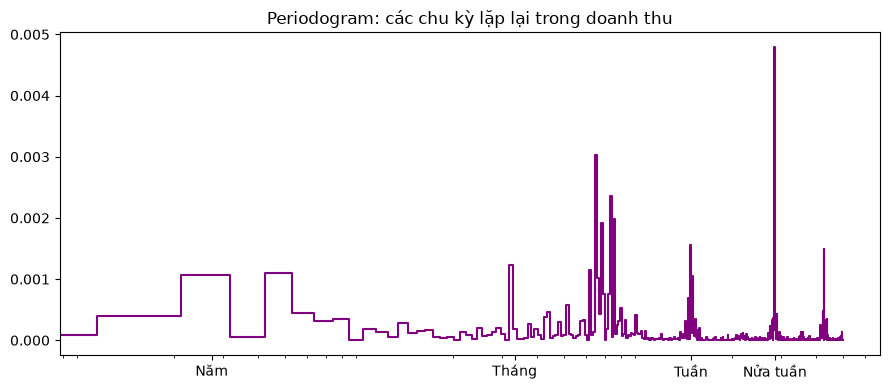

In [10]:
frequencies, spectrum = periodogram(daily_sales, detrend='linear', scaling='spectrum')
fig, ax = plt.subplots(figsize=(9, 4))
ax.step(frequencies, spectrum, color='purple')
ax.set_xscale('log')
ax.set_xticks([1 / 365, 1 / 30, 1 / 7, 1 / 3.5])
ax.set_xticklabels(['Năm', 'Tháng', 'Tuần', 'Nửa tuần'])
ax.set_title('Periodogram: các chu kỳ lặp lại trong doanh thu')
save_fig('periodogram')

**Nhận xét:** các đỉnh cao nhất nằm ở chu kỳ **tuần** và nửa tuần (hệ quả của chu kỳ tuần), sau đó là chu kỳ năm. Vì vậy dùng biến giả thứ trong tuần cho chu kỳ tuần và chuỗi Fourier cho chu kỳ năm.

Số đặc trưng thời gian: 28


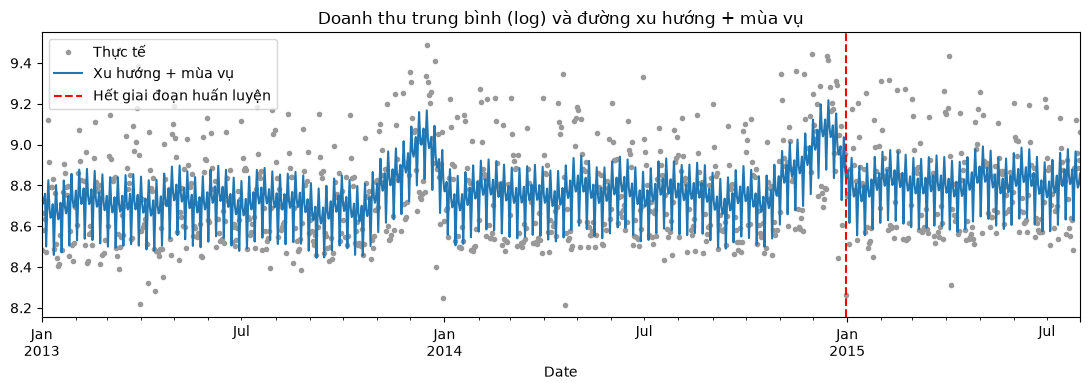

In [11]:
# [UPDATED] Bỏ Fourier theo tuần vì 6 biến giả thứ trong tuần (seasonal=True) đã mô tả đủ chu kỳ tuần
fourier_year = CalendarFourier(freq='YE', order=10)
dp = DeterministicProcess(index=daily_sales.index, constant=True, order=1, seasonal=True,
                          additional_terms=[fourier_year], drop=True)
X_time = dp.in_sample()

# [UPDATED] Chỉ khớp mô hình trên giai đoạn huấn luyện để không "nhìn trước" dữ liệu kiểm định/kiểm tra (tránh rò rỉ dữ liệu)
is_train_day = X_time.index <= TRAIN_END
trend_model = LinearRegression(fit_intercept=False).fit(X_time[is_train_day], daily_sales[is_train_day])
daily_fitted = pd.Series(trend_model.predict(X_time), index=X_time.index)
print('Số đặc trưng thời gian:', X_time.shape[1])

ax = daily_sales.plot(style='.', color='0.6', figsize=(11, 4), label='Thực tế')
daily_fitted.plot(ax=ax, linewidth=1.5, color='tab:blue', label='Xu hướng + mùa vụ')
ax.axvline(pd.Timestamp(TRAIN_END), color='red', linestyle='--', label='Hết giai đoạn huấn luyện')
ax.set_title('Doanh thu trung bình (log) và đường xu hướng + mùa vụ')
ax.legend()
save_fig('trend_seasonal_fit')

## 3.5 Đặc trưng độ trễ (lag)

Phần còn lại sau khi bỏ xu hướng và mùa vụ (phần dư) được dùng để chọn độ trễ bằng biểu đồ PACF.

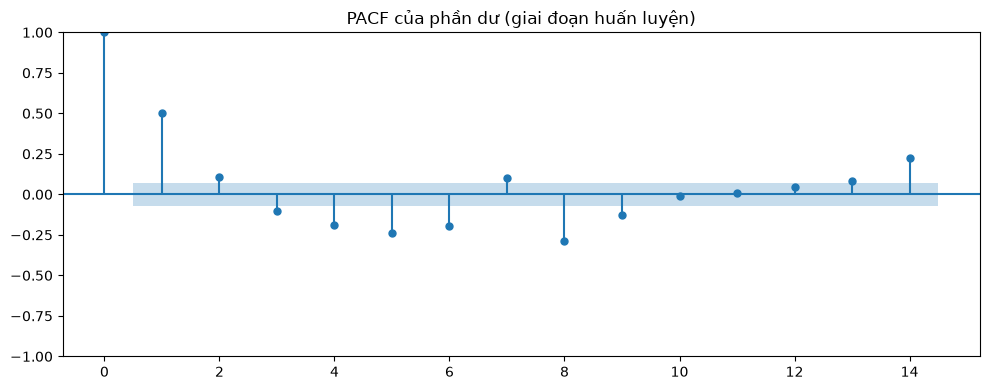

In [12]:
y_deseason = daily_sales - daily_fitted
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(y_deseason[:TRAIN_END], lags=14, ax=ax)
ax.set_title('PACF của phần dư (giai đoạn huấn luyện)')
save_fig('pacf')

**Nhận xét:** độ trễ 1 có PACF lớn nhất (≈ 0,50), độ trễ 8 nổi bật tiếp theo (≈ −0,28). Vì vậy chọn **lag 1 và lag 8**.

In [13]:
# [UPDATED] Sắp xếp theo cửa hàng và ngày trước khi dịch lùi, để lag đúng là "ngày bán trước đó" của chính cửa hàng đó
my_data = my_data.sort_values(['Store', 'Date']).reset_index(drop=True)
my_data['lag_1'] = my_data.groupby('Store')['Sales'].shift(1)
my_data['lag_8'] = my_data.groupby('Store')['Sales'].shift(8)

# Phần dư của toàn chuỗi ở 1 và 8 ngày trước, ghép cùng các đặc trưng thời gian theo ngày
resid_lags = pd.DataFrame({'lag_1_resid': y_deseason.shift(1), 'lag_8_resid': y_deseason.shift(8)})
time_features = X_time.join(resid_lags)
my_data = my_data.merge(time_features, left_on='Date', right_index=True, how='left')
my_data = my_data.dropna(subset=['lag_1', 'lag_8', 'lag_1_resid', 'lag_8_resid']).reset_index(drop=True)
print(my_data.shape)

(835418, 50)


## 3.6 Chia tập dữ liệu và lưu kết quả

In [14]:
# [UPDATED] Một cách chia tập duy nhất cho cả hai mô hình (trước đây tập train của LightGBM chứa cả 01/2015, trùng với tập kiểm định)
my_data['Split'] = np.select([my_data['Date'] <= TRAIN_END, my_data['Date'] <= VALID_END], ['train', 'valid'], default='test')

# [UPDATED] Đổi cột chữ sang kiểu category để LightGBM xử lý trực tiếp, thay cho Target Encoding
for col in ['StoreType', 'Assortment', 'StateHoliday']:
    my_data[col] = my_data[col].astype('category')

BASE_FEATURES = ['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitorLongevity', 'Promo2',
                 'Promo2SinceWeek', 'Promo2SinceYear', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
                 'Day', 'Month', 'Year', 'Cluster']
FEATURES = {
    'lgbm': BASE_FEATURES + ['lag_1', 'lag_8'],
    'hybrid_linear': list(X_time.columns) + ['lag_1', 'lag_8'],
    'hybrid_boost': BASE_FEATURES + ['lag_1_resid', 'lag_8_resid'],
}
my_data.groupby('Split', sort=False)['Date'].agg(['min', 'max', 'size'])

,min,max,size
Split,,,
train,2013-01-09,2014-12-31,639389
valid,2015-01-01,2015-04-30,111539
test,2015-05-01,2015-07-31,84490


In [15]:
# [UPDATED] Lưu bảng đặc trưng để notebook 04 đọc lại (trước đây các notebook phải chạy chung một kernel)
pd.to_pickle({'data': my_data, 'features': FEATURES}, PROCESSED_DIR / 'features.pkl')
print({name: len(cols) for name, cols in FEATURES.items()})

{'lgbm': 18, 'hybrid_linear': 30, 'hybrid_boost': 18}
